<a href="https://colab.research.google.com/github/moloco/docs/blob/anoop-collab/Copy_of_campaign_status.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import json
import os
import sys
import time
from datetime import datetime, timedelta

import matplotlib
import numpy as np
import pandas as pd

from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
from matplotlib import cm, pylab
import matplotlib.pyplot as plt

from google.cloud import storage

project='focal-elf-631'
client = bigquery.Client(project)

In [ ]:

def get_revenue_by_minute(campaigns, start_dt, end_dt):
  """ extract revenue info by minute """
  client = bigquery.Client(project)

  dt_s = start_dt
  dt_e = end_dt
  query_text = f"""
declare camps string default '{campaigns}';
declare dt_s string default '{dt_s}';
declare dt_e string default '{dt_e}';

select
  campaign, date_minute, budget, max_revenue revenue,
  spent, imp_cnt, internal_winner_cnt, prc_cnt,
  tcm, core_pred, wrapper_pred, wrapper_normalizer, normalizer_1, normalizer_99
from `moloco-data-prod.younghan.spending_summary`
where
  campaign in unnest(split(camps, ':'))
  and date between parse_date('%y%m%d', dt_s) and parse_date('%y%m%d', dt_e)
order by date_minute
"""
  result = client.query(query_text)
  return result.to_dataframe()


def spending_chart(campaign, start_dt='221001', end_dt='221001', res=None):
  """[summary]
  Draw spending chart. save figure for slack message

  Args:
      campaign ([string]): [campaign id]
      res ([pd.DataFrame], optional): [Revenue by miniute]. Defaults to None.

  Returns:
      [string]: [path name of the saved figure]
  """
  if res is None:
    res = get_revenue_by_minute(campaign, start_dt, end_dt)
  for col in ['budget', 'revenue', 'tcm', 'core_pred', 'wrapper_pred',
              'wrapper_normalizer', 'normalizer_1', 'normalizer_99',
              'spent', 'imp_cnt', 'internal_winner_cnt', 'prc_cnt'
              ]:
    assert col in res.columns
  now = datetime.now().strftime('%y%m%d_%H%M%S')
  save_dir= '~/Downloads/plot'
  save_name = f'{save_dir}/{now}_{campaign}.png'
  fig, (ax1, ax2, ax3) = plt.subplots(3, 1)
  fig.set_size_inches(18, 18)
  color_map = cm.Paired
  colors = color_map(np.linspace(0, 1, 4))
  x_min = res.date_minute.min() - 0.05 * (res.date_minute.max() - res.date_minute.min())
  x_max = res.date_minute.max() + 0.05 * (res.date_minute.max() - res.date_minute.min())
  for i, col in enumerate(['budget', 'revenue']):
    ax1.scatter(res.date_minute, res[col], color=colors[i], s=10, label=col)
  ax1.set_xlim(x_min, x_max)
  ax1.legend(loc=2, fontsize=10)
  ax1.grid()
  ax1.set_xlabel('UTC time', fontsize=20)
  ax1.set_ylabel('Revenue', fontsize=20)
  ax1.set_title(f'Revenue for {campaign}', fontsize=30)
  if (res[['tcm', 'core_pred', 'wrapper_pred', 'wrapper_normalizer']] > 0).sum().sum() > 0:
    for i, col in enumerate(['tcm', 'core_pred', 'wrapper_pred', 'wrapper_normalizer']):
      # eliminate non-positive numbers to draw in log-scale.
      res.loc[~(res[col] > 0), col] = np.nan
      if (res[col] > 0).sum() > 0:
        ax2.scatter(res.date_minute, res[col], color=colors[i], s=10, label=col)
        if col == 'wrapper_normalizer':
          ax2.fill_between(res.date_minute,
                           res['normalizer_99'],
                           res['normalizer_1'],
                           color=colors[3],
                           alpha=0.1,
                           label='normalizer_p1_p99')
    ax2.set_xlim(x_min, x_max)
    ax2.legend(loc=3, fontsize=10)
    ax2.set_yscale('log')
    ax2.grid()
    ax2.set_xlabel('UTC time', fontsize=20)
    ax2.set_ylabel('Tcm and predictions(Log scale)', fontsize=20)
    y_min = np.floor(np.log10(res[['tcm', 'core_pred', 'wrapper_pred', 'wrapper_normalizer']].min().min())) - 0.1
    if y_min < -6.1:  # eliminate numbers < 10^-6
      y_min = -6.1
    y_max = np.ceil(np.log10(res[['tcm', 'core_pred', 'wrapper_pred', 'wrapper_normalizer']].max().max())) + 0.1
    ax2.set_ylim(10**y_min, 10**y_max)
  res['spent_1000'] = res['spent'] * 1000.
  res['prc_cnt'] = res['prc_cnt'] * 1000.
  res['internal_winner_cnt'] = res['internal_winner_cnt'] * 1000.
  if (res[['imp_cnt','prc_cnt','spent_1000']] > 0).sum().sum() > 0:
    for i, col in enumerate(['spent_1000', 'imp_cnt', 'internal_winner_cnt', 'prc_cnt', ]):
      ax3.scatter(res.date_minute, res[col], color=colors[i], s=10, label=col)
    ax3.set_xlim(x_min, x_max)
    ax3.legend(loc=2, fontsize=10)
    ax3.set_yscale('log')
    ax3.grid()
    y_max = np.ceil(np.log10(res[['imp_cnt', 'prc_cnt', 'spent_1000']].max().max())) + 0.1
    y_min = np.floor(np.log10(res[['imp_cnt', 'prc_cnt', 'spent_1000']].min().min() + 0.001)) - 0.1
    ax3.set_ylim(10**y_min, 10**y_max)
  fig.tight_layout()
  plt.show()
  return res


ValueError: Axis limits cannot be NaN or Inf

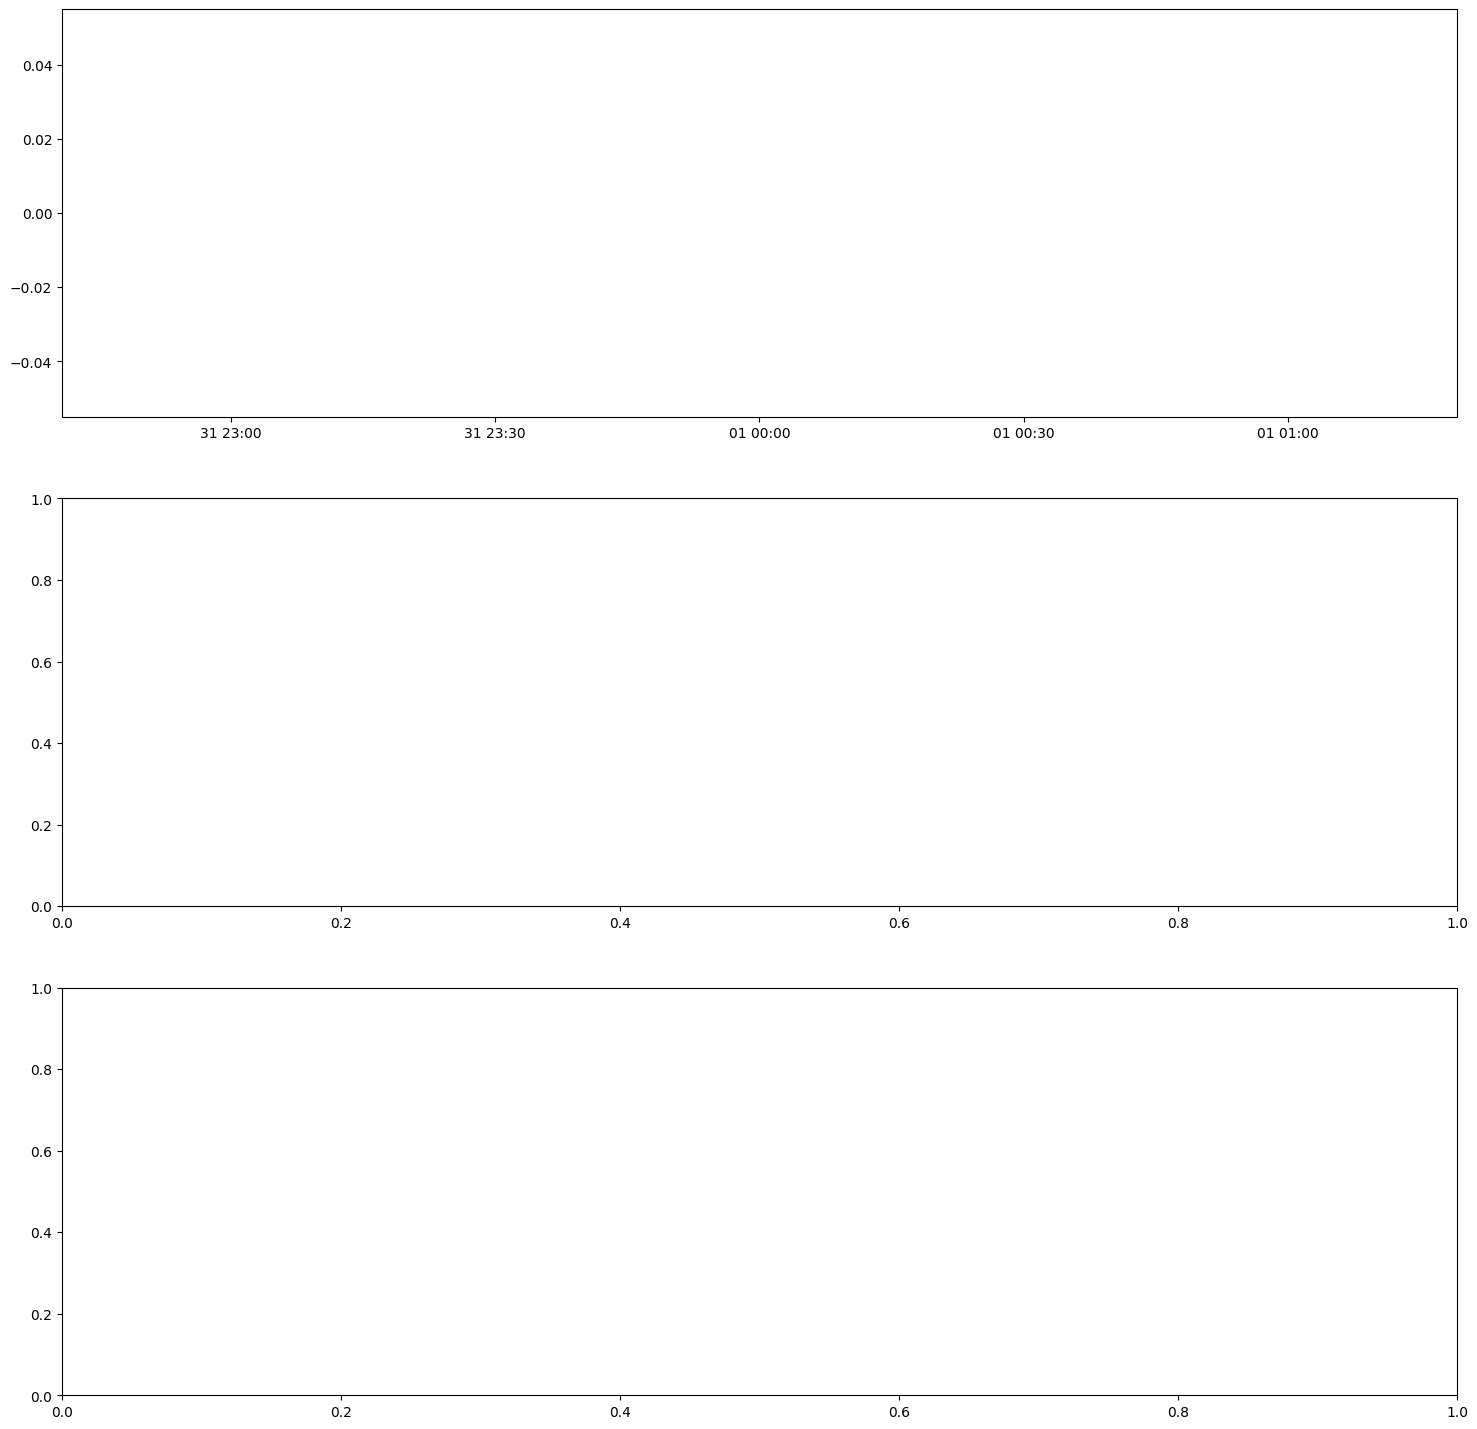

In [ ]:
# Single campaign chart
spending_chart('kuUEP2GIJx3PGoaj','250323','250325')

In [ ]:
# multiple campaigns for single query
campaign_list = ["kuUEP2GIJx3PGoaj"]
res=get_revenue_by_minute(':'.join(campaign_list), '241005','241005')

In [ ]:
for campaign in res.campaign.unique():
  spending_chart(campaign,'231029','231030',res=res[res.campaign==campaign])